# Model 1 – Livelihood Recommendation (training)


In [1]:
from importlib.metadata import version
import subprocess, sys
if version("scikit-learn") != "1.6.1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "scikit-learn==1.6.1"])
    print("Installed scikit-learn 1.6.1 -> now click Runtime > Restart session, then Run all.")
else:
    print("scikit-learn 1.6.1 already in use. OK.")

scikit-learn 1.6.1 already in use. OK.


## 1. Setup

In [2]:
import json, datetime
import numpy as np
import pandas as pd
import joblib, sklearn
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

SEED = 42
DATA_FILE = "model1_training.csv"
AREA_FILE = "area_index.csv"
assert sklearn.__version__ == "1.6.1", "Wrong scikit-learn version: click Runtime > Restart session, then Run all."

## 2. Upload the files (skipped automatically if they are already in Colab)

In [3]:
import os
needed = [DATA_FILE] + ([AREA_FILE] if AREA_FILE else [])
missing = [f for f in needed if not os.path.exists(f)]
if not missing:
    print("All files already here:", needed)
else:
    try:
        from google.colab import files
        print("Please upload:", missing)
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Missing files: {missing}")

All files already here: ['model1_training.csv', 'area_index.csv']


## 3. Load the data

In [4]:
df = pd.read_csv(DATA_FILE)
print(df.shape)
print(df["is_synthetic"].value_counts().rename({False: "real", True: "generated"}))
print()
print(pd.crosstab(df["category"], df["is_synthetic"].map({False: "real", True: "generated"})))

(363, 11)
is_synthetic
real         301
generated     62
Name: count, dtype: int64

is_synthetic                       generated  real
category                                          
AGRICULTURE & PLANTATION CROPS             0    47
BEAUTY AND WELLNESS                       20     0
CONSTRUCTION, BUILDING AND REPAIR          0    27
FOOD PROCESSING & PRODUCTION              16     9
GARMENT TEXTILE, HANDICRAFTS               0    44
LIVESTOCK & ANIMAL HUSBANDRY               0   103
OTHER                                      6    19
TRADE                                      0    52
TRANSPORT & LOGISTICS                     20     0


## 4. Optional: add the BRIGHT area index (joined by district)

In [5]:
area_cols = []
if AREA_FILE:
    area = pd.read_csv(AREA_FILE)
    area_cols = [c for c in area.columns if c != "district"]
    df = df.merge(area, on="district", how="left")
    print("Area columns added:", area_cols)
else:
    print("No area file yet - training on household features only")

Area columns added: ['food_insecurity_score', 'debt_pct', 'land_pct']


## 5. Features and label

In [6]:
cat_cols = ["district", "ds_division", "gender", "female_headed", "disability", "aswesuma_category"]
num_cols = ["age"] + area_cols
FEATURES = cat_cols + num_cols
TARGET = "category"

X = df[FEATURES].copy()
for c in cat_cols:
    X[c] = X[c].astype("string").fillna("Unknown")      # missing -> "Unknown"
y = df[TARGET]
real = ~df["is_synthetic"]
print("Features:", FEATURES)

Features: ['district', 'ds_division', 'gender', 'female_headed', 'disability', 'aswesuma_category', 'age', 'food_insecurity_score', 'debt_pct', 'land_pct']


## 6. Split: test = real rows only; train = remaining real rows + all generated rows

In [7]:
real_idx = df.index[real]
train_real_idx, test_idx = train_test_split(
    real_idx, test_size=0.2, random_state=SEED, stratify=y[real_idx])
train_idx = train_real_idx.union(df.index[~real])

X_train, y_train = X.loc[train_idx], y.loc[train_idx]
X_test,  y_test  = X.loc[test_idx],  y.loc[test_idx]
print("Train rows:", len(X_train), "| Test rows (real only):", len(X_test))

Train rows: 302 | Test rows (real only): 61


## 7. Model: prepare inputs + Logistic Regression

In [8]:
prep = ColumnTransformer([
    ("cat", Pipeline([("fill", SimpleImputer(strategy="constant", fill_value="Unknown")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
    ("num", Pipeline([("fill", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), num_cols),
])

pipe = Pipeline([
    ("prep", prep),
    ("model", LogisticRegression(max_iter=2000, random_state=SEED)),
])

# only one setting is tuned: C (regularisation strength), chosen by 5-fold cross-validation
search = GridSearchCV(pipe, {"model__C": [0.1, 1, 10]},
                      cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="accuracy")
search.fit(X_train, y_train)
model = search.best_estimator_
print("Best C:", search.best_params_["model__C"])

Best C: 0.1


## 8. Evaluate on real test rows

In [9]:
def top_k_accuracy(model, X, y, k=3):
    proba = model.predict_proba(X)
    top = np.argsort(proba, axis=1)[:, -k:]
    classes = model.classes_
    return np.mean([y_i in classes[row] for y_i, row in zip(y, top)])

pred = model.predict(X_test)
top1 = accuracy_score(y_test, pred)
top3 = top_k_accuracy(model, X_test, y_test, 3)
baseline = (y_test == y_train.value_counts().idxmax()).mean()      # always guess the biggest class
random3 = 3 / len(model.classes_)

print(f"Top-1 accuracy : {top1:.2f}")
print(f"Top-3 accuracy : {top3:.2f}")
print(f"Baseline top-1 (always '{y_train.value_counts().idxmax()}'): {baseline:.2f}")
print(f"Random top-3   : {random3:.2f}")
print()
print(classification_report(y_test, pred, zero_division=0))
print(pd.DataFrame(confusion_matrix(y_test, pred, labels=model.classes_),
                   index=model.classes_, columns=[c[:8] for c in model.classes_]))

Top-1 accuracy : 0.39
Top-3 accuracy : 0.69
Baseline top-1 (always 'LIVESTOCK & ANIMAL HUSBANDRY'): 0.34
Random top-3   : 0.33

                                   precision    recall  f1-score   support

   AGRICULTURE & PLANTATION CROPS       0.00      0.00      0.00         9
CONSTRUCTION, BUILDING AND REPAIR       0.00      0.00      0.00         5
     FOOD PROCESSING & PRODUCTION       0.00      0.00      0.00         2
     GARMENT TEXTILE, HANDICRAFTS       0.00      0.00      0.00         9
     LIVESTOCK & ANIMAL HUSBANDRY       0.46      0.86      0.60        21
                            OTHER       0.00      0.00      0.00         4
                            TRADE       0.33      0.55      0.41        11

                         accuracy                           0.39        61
                        macro avg       0.11      0.20      0.14        61
                     weighted avg       0.22      0.39      0.28        61

                                   AGRICULT 

## 8b. Stability check: repeat the real train/test split 10 times

In [10]:
from sklearn.base import clone
res = []
for s in range(10):
    tr_r, te = train_test_split(real_idx, test_size=0.2, random_state=s, stratify=y[real_idx])
    tr = tr_r.union(df.index[~real])
    m = clone(model).fit(X.loc[tr], y.loc[tr])
    p = m.predict(X.loc[te])
    res.append((accuracy_score(y.loc[te], p), top_k_accuracy(m, X.loc[te], y.loc[te], 3)))
res = np.array(res)
print(f"Top-1 mean over 10 splits: {res[:,0].mean():.2f}  (+/- {res[:,0].std():.2f})")
print(f"Top-3 mean over 10 splits: {res[:,1].mean():.2f}  (+/- {res[:,1].std():.2f})")

Top-1 mean over 10 splits: 0.37  (+/- 0.02)
Top-3 mean over 10 splits: 0.64  (+/- 0.04)


## 9. Which inputs matter (for the viva)

In [11]:
names = model.named_steps["prep"].get_feature_names_out()
coef = model.named_steps["model"].coef_
classes = model.classes_
for i, c in enumerate(classes):
    top = np.argsort(coef[i])[-4:][::-1]
    print(f"{c}:")
    for j in top:
        print(f"    {names[j]}  ({coef[i][j]:+.2f})")

AGRICULTURE & PLANTATION CROPS:
    cat__ds_division_Lunugala  (+0.34)
    num__age  (+0.33)
    cat__female_headed_Yes  (+0.11)
    cat__aswesuma_category_Poor  (+0.07)
BEAUTY AND WELLNESS:
    cat__gender_Female  (+0.39)
    cat__female_headed_Yes  (+0.13)
    cat__disability_Unknown  (+0.10)
    cat__aswesuma_category_Severely Poor  (+0.07)
CONSTRUCTION, BUILDING AND REPAIR:
    cat__aswesuma_category_Poor  (+0.09)
    cat__ds_division_Mahiyanganaya  (+0.07)
    num__food_insecurity_score  (+0.06)
    num__land_pct  (+0.06)
FOOD PROCESSING & PRODUCTION:
    cat__female_headed_No  (+0.09)
    num__age  (+0.07)
    cat__aswesuma_category_Severely Poor  (+0.07)
    cat__gender_Male  (+0.06)
GARMENT TEXTILE, HANDICRAFTS:
    cat__ds_division_Mahiyanganaya  (+0.16)
    cat__gender_Female  (+0.12)
    cat__female_headed_No  (+0.12)
    cat__aswesuma_category_Poor  (+0.08)
LIVESTOCK & ANIMAL HUSBANDRY:
    cat__aswesuma_category_Severely Poor  (+0.23)
    cat__female_headed_Yes  (+0.20)
  

## 10. Sample prediction (same shape the API will use)

In [12]:
sample = pd.DataFrame([{
    "district": "Badulla", "ds_division": "Passara", "gender": "Female", "female_headed": "Yes",
    "disability": "No", "aswesuma_category": "Poor", "age": 38, **{c: np.nan for c in area_cols}}])
proba = model.predict_proba(sample[FEATURES])[0]
for i in np.argsort(proba)[::-1][:3]:
    print(f"{classes[i]}: {proba[i]*100:.0f}%")

LIVESTOCK & ANIMAL HUSBANDRY: 32%
AGRICULTURE & PLANTATION CROPS: 15%
TRADE: 14%


## 11. Save the model and its info file
The model is trained with scikit-learn 1.6.1 (see step 0), the same version as the backend. Copy the two saved files (`model_v1.joblib`, `model_v1_info.json`) into the backend `model_1_recommend/artifacts/` folder.

In [13]:
joblib.dump(model, "model_v1.joblib")
info = {
    "model": "LogisticRegression (multinomial)",
    "version": "v1",
    "trained_on": str(datetime.date.today()),
    "sklearn_version": sklearn.__version__,
    "features": FEATURES, "categorical": cat_cols, "numeric": num_cols,
    "classes": list(classes),
    "rows_train": int(len(X_train)), "rows_test_real": int(len(X_test)),
    "rows_generated_in_train": int(df.loc[train_idx, "is_synthetic"].sum()),
    "best_C": search.best_params_["model__C"],
    "metrics_real_test": {"top1": round(top1, 3), "top3": round(top3, 3),
                          "baseline_top1": round(float(baseline), 3), "random_top3": round(random3, 3),
                          "top1_mean_10_splits": round(res[:,0].mean(), 3), "top3_mean_10_splits": round(res[:,1].mean(), 3)},
    "notes": "Beauty and Transport have only generated training rows; no real test for them.",
}
json.dump(info, open("model_v1_info.json", "w"), indent=2)
print(json.dumps(info, indent=2))

{
  "model": "LogisticRegression (multinomial)",
  "version": "v1",
  "trained_on": "2026-10-18",
  "sklearn_version": "1.6.1",
  "features": [
    "district",
    "ds_division",
    "gender",
    "female_headed",
    "disability",
    "aswesuma_category",
    "age",
    "food_insecurity_score",
    "debt_pct",
    "land_pct"
  ],
  "categorical": [
    "district",
    "ds_division",
    "gender",
    "female_headed",
    "disability",
    "aswesuma_category"
  ],
  "numeric": [
    "age",
    "food_insecurity_score",
    "debt_pct",
    "land_pct"
  ],
  "classes": [
    "AGRICULTURE & PLANTATION CROPS",
    "BEAUTY AND WELLNESS",
    "CONSTRUCTION, BUILDING AND REPAIR",
    "FOOD PROCESSING & PRODUCTION",
    "GARMENT TEXTILE, HANDICRAFTS",
    "LIVESTOCK & ANIMAL HUSBANDRY",
    "OTHER",
    "TRADE",
    "TRANSPORT & LOGISTICS"
  ],
  "rows_train": 302,
  "rows_test_real": 61,
  "rows_generated_in_train": 62,
  "best_C": 0.1,
  "metrics_real_test": {
    "top1": 0.393,
    "top3": 0

In [14]:
try:
    from google.colab import files
    files.download("model_v1.joblib"); files.download("model_v1_info.json")
except ImportError:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Experiments
Everything below only **tests** the model. It does not change the saved `model_v1.joblib`.
All tests use the same rule as above: the test rows are real rows only.

1. Algorithm comparison
2. Which inputs matter (ablation)
3. Results per livelihood category
4. Learning curve
5. Cross-district test
6. BRIGHT district-mix adjustment test

In [15]:
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

BEST_C = search.best_params_["model__C"]

def build_prep(cats, nums):
    steps = []
    if cats:
        steps.append(("cat", Pipeline([("fill", SimpleImputer(strategy="constant", fill_value="Unknown")),
                                       ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cats))
    if nums:
        steps.append(("num", Pipeline([("fill", SimpleImputer(strategy="median")),
                                       ("scale", StandardScaler())]), nums))
    return ColumnTransformer(steps)

def make_pipe(est, cats=None, nums=None):
    cats = cat_cols if cats is None else cats
    nums = num_cols if nums is None else nums
    return Pipeline([("prep", build_prep(cats, nums)), ("model", est)])

# the same 10 real train/test splits are used for every comparison
SPLITS = []
for s in range(10):
    tr_r, te = train_test_split(real_idx, test_size=0.2, random_state=s, stratify=y[real_idx])
    SPLITS.append((tr_r.union(df.index[~real]), te))

def evaluate(make_est, cats=None, nums=None):
    cols = (cat_cols if cats is None else cats) + (num_cols if nums is None else nums)
    r = []
    for tr, te in SPLITS:
        m = make_pipe(make_est(), cats, nums).fit(X.loc[tr, cols], y.loc[tr])
        p = m.predict(X.loc[te, cols])
        r.append((accuracy_score(y.loc[te], p), top_k_accuracy(m, X.loc[te, cols], y.loc[te], 3)))
    r = np.array(r)
    return r[:, 0].mean(), r[:, 0].std(), r[:, 1].mean(), r[:, 1].std()

## 12.1 Algorithm comparison
Same inputs, same 10 splits. Why Logistic Regression: it is simple, it gives probabilities (scores) and its coefficients give the "reasons" shown in the API.

,Top-1,Top-1 std,Top-3,Top-3 std
Algorithm,,,,
Baseline (always biggest class),0.344,0.000,0.672,0.000
Logistic Regression (chosen),0.374,0.023,0.636,0.041
Decision Tree,0.295,0.059,0.511,0.046
Random Forest,0.221,0.047,0.544,0.054
Gradient Boosting,0.231,0.036,0.569,0.086


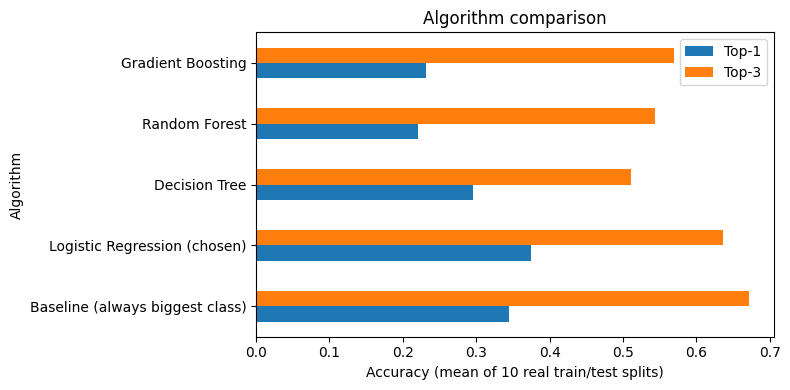

In [16]:
algos = {
    "Baseline (always biggest class)": lambda: DummyClassifier(strategy="prior"),
    "Logistic Regression (chosen)":    lambda: LogisticRegression(C=BEST_C, max_iter=2000, random_state=SEED),
    "Decision Tree":                   lambda: DecisionTreeClassifier(max_depth=5, random_state=SEED),
    "Random Forest":                   lambda: RandomForestClassifier(n_estimators=200, random_state=SEED),
    "Gradient Boosting":               lambda: GradientBoostingClassifier(random_state=SEED),
}
rows = []
for name, make in algos.items():
    a1, s1, a3, s3 = evaluate(make)
    rows.append({"Algorithm": name, "Top-1": round(a1, 3), "Top-1 std": round(s1, 3), "Top-3": round(a3, 3), "Top-3 std": round(s3, 3)})
algo_table = pd.DataFrame(rows).set_index("Algorithm")
display(algo_table)

ax = algo_table[["Top-1", "Top-3"]].plot.barh(figsize=(8, 4))
ax.set_xlabel("Accuracy (mean of 10 real train/test splits)"); ax.set_title("Algorithm comparison")
plt.tight_layout(); plt.show()

## 12.2 Which inputs matter (ablation)
Remove one input at a time, retrain, and see how much the Top-3 accuracy drops. A bigger drop means the input matters more.
(The 3 area values are removed together, because they are looked up from the district.)

All inputs: Top-1 0.374 | Top-3 0.636


,Top-1,Top-3,Top-3 drop
Removed input,,,
ds_division,0.369,0.628,0.008
aswesuma_category,0.369,0.631,0.005
age,0.375,0.634,0.002
district,0.372,0.636,0.000
"area values (food insecurity, debt, land)",0.367,0.643,-0.007
disability,0.375,0.644,-0.008
female_headed,0.377,0.648,-0.011
gender,0.369,0.677,-0.041


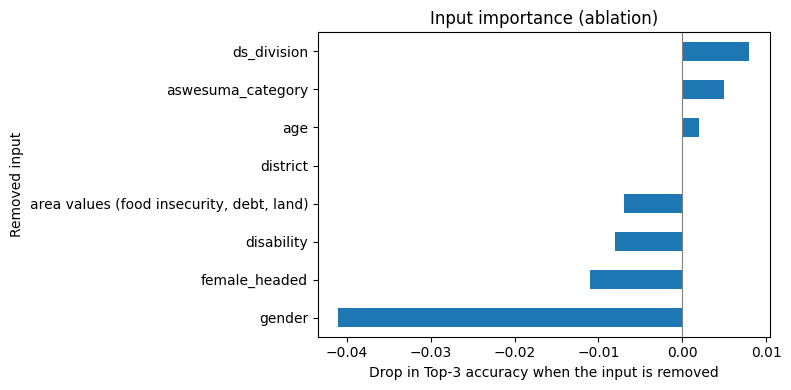

In [17]:
full = evaluate(lambda: LogisticRegression(C=BEST_C, max_iter=2000, random_state=SEED))
groups = {c: ([c], []) for c in cat_cols}
groups["age"] = ([], ["age"])
if area_cols:
    groups["area values (food insecurity, debt, land)"] = ([], area_cols)

rows = []
for name, (dc, dn) in groups.items():
    cats = [c for c in cat_cols if c not in dc]
    nums = [c for c in num_cols if c not in dn]
    a1, _, a3, _ = evaluate(lambda: LogisticRegression(C=BEST_C, max_iter=2000, random_state=SEED), cats, nums)
    rows.append({"Removed input": name, "Top-1": round(a1, 3), "Top-3": round(a3, 3),
                 "Top-3 drop": round(full[2] - a3, 3)})
abl = pd.DataFrame(rows).set_index("Removed input").sort_values("Top-3 drop", ascending=False)
print(f"All inputs: Top-1 {full[0]:.3f} | Top-3 {full[2]:.3f}")
display(abl)

ax = abl["Top-3 drop"].sort_values().plot.barh(figsize=(8, 4))
ax.set_xlabel("Drop in Top-3 accuracy when the input is removed"); ax.set_title("Input importance (ablation)")
ax.axvline(0, color="grey", lw=0.8); plt.tight_layout(); plt.show()

## 12.3 Results per livelihood category
Shows where the model is strong and where it is weak. Categories with 0 support have no real test rows.

,precision,recall,f1-score,support
AGRICULTURE & PLANTATION CROPS,0.00,0.00,0.00,9.0
BEAUTY AND WELLNESS,0.00,0.00,0.00,0.0
"CONSTRUCTION, BUILDING AND REPAIR",0.00,0.00,0.00,5.0
FOOD PROCESSING & PRODUCTION,0.00,0.00,0.00,2.0
"GARMENT TEXTILE, HANDICRAFTS",0.00,0.00,0.00,9.0
LIVESTOCK & ANIMAL HUSBANDRY,0.46,0.86,0.60,21.0
OTHER,0.00,0.00,0.00,4.0
TRADE,0.33,0.55,0.41,11.0
TRANSPORT & LOGISTICS,0.00,0.00,0.00,0.0


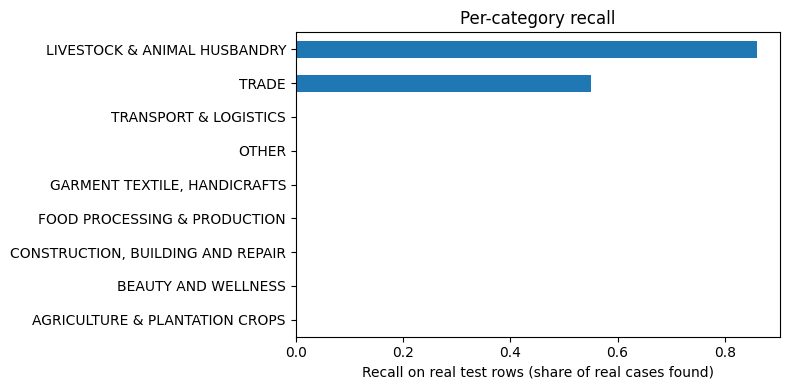

In [18]:
rep = classification_report(y_test, pred, labels=list(classes), zero_division=0, output_dict=True)
per_class = pd.DataFrame({c: rep[c] for c in classes}).T[["precision", "recall", "f1-score", "support"]].round(2)
display(per_class)

ax = per_class["recall"].sort_values().plot.barh(figsize=(8, 4))
ax.set_xlabel("Recall on real test rows (share of real cases found)"); ax.set_title("Per-category recall")
plt.tight_layout(); plt.show()

## 12.4 Learning curve
Train on 25%, 50%, 75% and 100% of the training rows (random subsets, repeated 10 times), test on the same real test rows.
If the curve still rises at 100%, more labelled data would help.

,Top-1,Top-1 std,Top-3,Top-3 std
Training rows,,,,
76,0.375,0.036,0.639,0.060
151,0.389,0.029,0.666,0.045
226,0.384,0.026,0.700,0.026
302,0.393,0.000,0.689,0.000


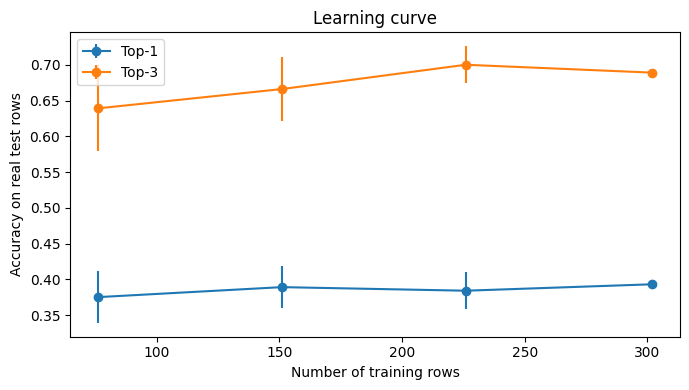

In [19]:
rng = np.random.RandomState(SEED)
rows = []
for frac in [0.25, 0.5, 0.75, 1.0]:
    t1, t3 = [], []
    for _ in range(10):
        n = int(round(frac * len(X_train)))
        idx = rng.choice(len(X_train), size=n, replace=False)
        m = clone(model).fit(X_train.iloc[idx], y_train.iloc[idx])
        t1.append(accuracy_score(y_test, m.predict(X_test)))
        t3.append(top_k_accuracy(m, X_test, y_test, 3))
    rows.append({"Training rows": n, "Top-1": np.mean(t1), "Top-1 std": np.std(t1), "Top-3": np.mean(t3), "Top-3 std": np.std(t3)})
lc = pd.DataFrame(rows).set_index("Training rows").round(3)
display(lc)

plt.figure(figsize=(7, 4))
plt.errorbar(lc.index, lc["Top-1"], yerr=lc["Top-1 std"], marker="o", label="Top-1")
plt.errorbar(lc.index, lc["Top-3"], yerr=lc["Top-3 std"], marker="o", label="Top-3")
plt.xlabel("Number of training rows"); plt.ylabel("Accuracy on real test rows")
plt.title("Learning curve"); plt.legend(); plt.tight_layout(); plt.show()

## 12.5 Cross-district test
Train on one district only, then test on the real rows of the other district (a district the model has never seen).

In [20]:
rows = []
for tr_d, te_d in [("Badulla", "Monaragala"), ("Monaragala", "Badulla")]:
    tr = df.index[df["district"] == tr_d]
    te = df.index[(df["district"] == te_d) & real]
    m = clone(model).fit(X.loc[tr], y.loc[tr])
    base = (y.loc[te] == y.loc[tr].value_counts().idxmax()).mean()
    rows.append({"Train on": tr_d, "Test on": te_d, "Test rows": len(te),
                 "Top-1": round(accuracy_score(y.loc[te], m.predict(X.loc[te])), 3),
                 "Top-3": round(top_k_accuracy(m, X.loc[te], y.loc[te], 3), 3),
                 "Baseline top-1": round(base, 3), "Random top-3": round(random3, 3)})
display(pd.DataFrame(rows).set_index("Train on"))

,Test on,Test rows,Top-1,Top-3,Baseline top-1,Random top-3
Train on,,,,,,
Badulla,Monaragala,104,0.163,0.606,0.154,0.333
Monaragala,Badulla,197,0.183,0.563,0.122,0.333


## 12.6 BRIGHT district-mix adjustment test
Idea: BRIGHT tells us what share of working people are in each livelihood category in every district.
We tried multiplying the model scores by (target district share ÷ training district share), raised to a power alpha, and re-normalising.
alpha = 0 means no adjustment. Needs `district_livelihood_shares.csv` in the Colab sidebar (made by the district shares notebook).

In [21]:
SHARES_FILE = "district_livelihood_shares.csv"
if not os.path.exists(SHARES_FILE):
    print("Skipped: put", SHARES_FILE, "in the Colab sidebar and run this cell again.")
else:
    shares = pd.read_csv(SHARES_FILE).set_index("district")
    rows = []
    for tr_d, te_d in [("Badulla", "Monaragala"), ("Monaragala", "Badulla")]:
        tr = df.index[df["district"] == tr_d]
        te = df.index[(df["district"] == te_d) & real]
        m = clone(model).fit(X.loc[tr], y.loc[tr])
        cl = m.classes_
        P = m.predict_proba(X.loc[te])
        ratio = shares.loc[te_d, cl].values.astype(float) / shares.loc[tr_d, cl].values.astype(float)
        yt = y.loc[te].values
        for alpha in [0, 0.25, 0.5, 1]:
            Q = P * ratio ** alpha
            Q = Q / Q.sum(axis=1, keepdims=True)
            top = np.argsort(-Q, axis=1)
            rows.append({"Train on": tr_d, "Test on": te_d, "alpha": alpha,
                         "Top-1": round(np.mean(cl[top[:, 0]] == yt), 3),
                         "Top-3": round(np.mean([yt[i] in cl[top[i, :3]] for i in range(len(yt))]), 3)})
    display(pd.DataFrame(rows).set_index(["Train on", "Test on", "alpha"]))

Top-1  Top-3
Train on   Test on    alpha              
Badulla    Monaragala 0.00   0.163  0.606
                      0.25   0.154  0.644
                      0.50   0.154  0.596
                      1.00   0.154  0.567
Monaragala Badulla    0.00   0.183  0.563
                      0.25   0.152  0.482
                      0.50   0.127  0.340
                      1.00   0.102  0.254

## How to read these experiments
- **12.1** shows other algorithms were tried and why Logistic Regression was chosen. Logistic Regression has the best Top-1. The "always biggest classes" baseline has a similar or higher Top-3, because the inputs carry little information.
- **12.2** shows which inputs carry information and which add little. The differences are small (inside the spread across splits), so no single input is strongly important.
- **12.3** shows where the model is strong and weak per category.
- **12.4** shows how accuracy changes with the amount of training data.
- **12.5** shows what happens in a district the model has never seen.
- **12.6** is a tested extension. Alpha > 0 does not give a consistent improvement over alpha = 0 (it helps in one direction and hurts in the other), so it is not used in the API. BRIGHT records current jobs, while the labels record livelihoods families plan to start, so the two do not match.